In [ ]:
!pip -q install kagglehub
import os, math, random, time, copy, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F, torchvision
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
warnings.filterwarnings("ignore")

device = "cuda" if torch.cuda.is_available() else "cpu"
use_amp = device == "cuda"
print("Device:", device, torch.cuda.get_device_name(0) if use_amp else "<-- GPU nahi! Runtime > Change runtime type > T4 GPU")

from google.colab import drive
drive.mount("/content/drive")
OUT = "/content/drive/MyDrive/retina_gan"
os.makedirs(OUT, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

Device: cuda Tesla T4
Mounted at /content/drive


In [ ]:
import kagglehub
DATA_SLUG = "sovitrath/diabetic-retinopathy-224x224-2019-data"
path = kagglehub.dataset_download(DATA_SLUG)
print("Downloaded to:", path)

CLASS_MAP = {"no_dr": 0, "mild": 1, "moderate": 2, "severe": 3, "proliferate_dr": 4}
rows = []
for root, dirs, files in os.walk(path):
    cname = os.path.basename(root).lower().replace(" ", "_")
    if cname in CLASS_MAP:
        for f in files:
            if f.lower().endswith((".png", ".jpg", ".jpeg")):
                rows.append((os.path.join(root, f), CLASS_MAP[cname]))
df = pd.DataFrame(rows, columns=["path", "grade"])
df["top"] = df.path.str.replace(path, "", regex=False).str.strip("/").str.split("/").str[0]
print(df.groupby(["top", "grade"]).size().unstack(fill_value=0))
print("Total images:", len(df), "(APTOS train mein 3662 hone chahiye)")

Using Colab cache for faster access to the 'diabetic-retinopathy-224x224-2019-data' dataset.
Downloaded to: /kaggle/input/diabetic-retinopathy-224x224-2019-data
grade              0    1    2    3    4
top                                     
colored_images  1805  370  999  193  295
Total images: 3662 (APTOS train mein 3662 hone chahiye)


grade
0    1805
1     370
2     999
3     193
4     295
Name: count, dtype: int64
Minority (grade 3-4) = 488 images = 13.3%


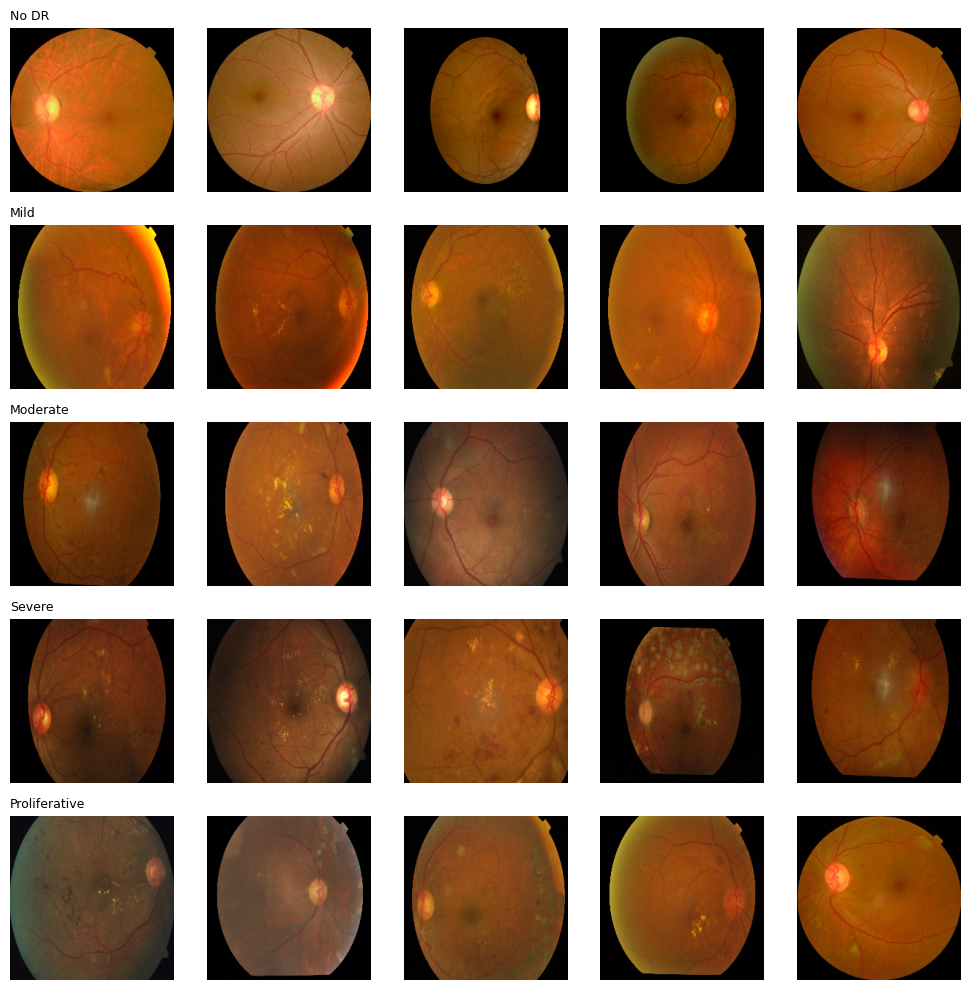

In [ ]:
SUBFOLDER = None   # agar ek se zyada top folder the, yahan naam likho, e.g. "colored_images"
if SUBFOLDER:
    df = df[df.top == SUBFOLDER].reset_index(drop=True)
df["label"] = (df.grade >= 3).astype(int)
print(df.grade.value_counts().sort_index())
print(f"Minority (grade 3-4) = {df.label.sum()} images = {df.label.mean()*100:.1f}%")

names = ["No DR", "Mild", "Moderate", "Severe", "Proliferative"]
fig, axs = plt.subplots(5, 5, figsize=(10, 10))
for g in range(5):
    sub = df[df.grade == g].sample(5, random_state=0)
    for j, p in enumerate(sub.path):
        axs[g, j].imshow(Image.open(p)); axs[g, j].axis("off")
    axs[g, 0].set_title(names[g], fontsize=9, loc="left")
plt.tight_layout(); plt.savefig(f"{OUT}/eda_samples.png", dpi=120); plt.show()

In [ ]:
IMG = 64
def load_img(p):
    return np.asarray(Image.open(p).convert("RGB").resize((IMG, IMG), Image.LANCZOS))

t0 = time.time()
X = np.stack([load_img(p) for p in df.path])
print(X.shape, f"{time.time()-t0:.0f}s")
X = torch.from_numpy(X).permute(0, 3, 1, 2).contiguous()
y = torch.tensor(df.label.values)

idx = np.arange(len(df))
tr, tmp = train_test_split(idx, test_size=0.30, stratify=df.grade.values, random_state=42)
va, te = train_test_split(tmp, test_size=0.50, stratify=df.grade.values[tmp], random_state=42)
Xtr, ytr, Xva, yva, Xte, yte = X[tr], y[tr], X[va], y[va], X[te], y[te]
for n, yy in [("train", ytr), ("val", yva), ("test", yte)]:
    print(f"{n}: {len(yy)} images, minority {int(yy.sum())} ({yy.float().mean()*100:.1f}%)")

(3662, 64, 64, 3) 46s
train: 2563 images, minority 342 (13.3%)
val: 549 images, minority 73 (13.3%)
test: 550 images, minority 73 (13.3%)


In [ ]:
NZ = 100
def aug_flip(x):
    for dim in (3, 2):
        m = torch.rand(x.size(0), device=x.device) < 0.5
        x = torch.where(m[:, None, None, None], x.flip(dim), x)
    return x

def winit(m):
    n = m.__class__.__name__
    if "Conv" in n:
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif "BatchNorm" in n:
        nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

def make_G(nz=NZ, ngf=64, img=IMG):
    n_up = int(math.log2(img // 4)); ch = ngf * 8
    L = [nn.ConvTranspose2d(nz, ch, 4, 1, 0, bias=False), nn.BatchNorm2d(ch), nn.ReLU(True)]
    for _ in range(n_up - 1):
        nxt = max(ch // 2, ngf)
        L += [nn.ConvTranspose2d(ch, nxt, 4, 2, 1, bias=False), nn.BatchNorm2d(nxt), nn.ReLU(True)]
        ch = nxt
    L += [nn.ConvTranspose2d(ch, 3, 4, 2, 1), nn.Tanh()]
    G = nn.Sequential(*L); G.apply(winit)
    return G

def make_D(kind, ndf=64, img=IMG):
    n_down = int(math.log2(img // 4)); L = []; cin = 3; ch = ndf
    for i in range(n_down):
        conv = nn.Conv2d(cin, ch, 4, 2, 1, bias=False)
        nn.init.normal_(conv.weight, 0.0, 0.02)
        if kind == "sn":
            L += [nn.utils.spectral_norm(conv), nn.LeakyReLU(0.2)]
        else:
            L += [conv, nn.GroupNorm(1, ch) if i > 0 else nn.Identity(), nn.LeakyReLU(0.2)]
        cin = ch; ch = min(ch * 2, ndf * 8)
    last = nn.Conv2d(cin, 1, 4, 1, 0)
    L += [nn.utils.spectral_norm(last) if kind == "sn" else last, nn.Flatten(0)]
    return nn.Sequential(*L)

In [ ]:
def train_dcgan(real, epochs=600, bs=64, lr=2e-4, seed=0):
    set_seed(seed)
    G, D = make_G().to(device), make_D("sn").to(device)
    oG = torch.optim.Adam(G.parameters(), lr, betas=(0.5, 0.999))
    oD = torch.optim.Adam(D.parameters(), lr, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss(); n = real.size(0)
    for ep in range(epochs):
        perm = torch.randperm(n, device=device)
        for i in range(0, n - bs + 1, bs):
            xr = aug_flip(real[perm[i:i + bs]])
            xf = G(torch.randn(bs, NZ, 1, 1, device=device))
            lD = bce(D(xr), torch.full((bs,), 0.9, device=device)) + \
                 bce(D(aug_flip(xf.detach())), torch.zeros(bs, device=device))
            oD.zero_grad(); lD.backward(); oD.step()
            lG = bce(D(aug_flip(xf)), torch.ones(bs, device=device))
            oG.zero_grad(); lG.backward(); oG.step()
        if ep % 100 == 0 or ep == epochs - 1:
            print(f"[DCGAN s{seed}] epoch {ep+1}/{epochs}  lossD {lD.item():.3f}  lossG {lG.item():.3f}")
    return G

def train_wgangp(real, g_steps=4000, n_critic=5, bs=64, lr=1e-4, lam=10.0, seed=0):
    set_seed(seed)
    G, D = make_G().to(device), make_D("critic").to(device)
    oG = torch.optim.Adam(G.parameters(), lr, betas=(0.0, 0.9))
    oD = torch.optim.Adam(D.parameters(), lr, betas=(0.0, 0.9))
    n = real.size(0)
    for step in range(g_steps):
        for _ in range(n_critic):
            xr = aug_flip(real[torch.randint(0, n, (bs,), device=device)])
            with torch.no_grad():
                xf = aug_flip(G(torch.randn(bs, NZ, 1, 1, device=device)))
            a = torch.rand(bs, 1, 1, 1, device=device)
            xh = (a * xr + (1 - a) * xf).requires_grad_(True)
            g = torch.autograd.grad(D(xh).sum(), xh, create_graph=True)[0]
            gp = ((g.flatten(1).norm(2, dim=1) - 1) ** 2).mean()
            wd = D(xr).mean() - D(xf).mean()
            lD = -wd + lam * gp
            oD.zero_grad(); lD.backward(); oD.step()
        lG = -D(aug_flip(G(torch.randn(bs, NZ, 1, 1, device=device)))).mean()
        oG.zero_grad(); lG.backward(); oG.step()
        if step % 500 == 0 or step == g_steps - 1:
            print(f"[WGAN-GP s{seed}] step {step+1}/{g_steps}  W-dist {wd.item():.3f}  lossG {lG.item():.3f}")
    return G

@torch.no_grad()
def synth(G, n, bs=256):
    out = []
    for i in range(0, n, bs):
        z = torch.randn(min(bs, n - i), NZ, 1, 1, device=device)
        out.append(((G(z) + 1) * 127.5).clamp(0, 255).round().byte().cpu())
    return torch.cat(out)

In [ ]:
GAN_SEEDS = [0, 1, 2]     # test mode: [0]
WGAN_STEPS = 4000         # test mode: 50
DCGAN_EPOCHS = 600        # test mode: 20
real_pos = (Xtr[ytr == 1].to(device).float() / 127.5) - 1
print("GAN training images:", real_pos.shape)

GENS = {"dcgan": {}, "wgangp": {}}
for kind in GENS:
    for s in GAN_SEEDS:
        f = f"{OUT}/G_{kind}_{IMG}_{s}.pt"
        if os.path.exists(f):
            G = make_G().to(device); G.load_state_dict(torch.load(f, map_location=device))
            print("loaded", f)
        else:
            t0 = time.time()
            G = train_dcgan(real_pos, DCGAN_EPOCHS, seed=s) if kind == "dcgan" else train_wgangp(real_pos, WGAN_STEPS, seed=s)
            torch.save(G.state_dict(), f); print(f"{kind} seed {s}: {(time.time()-t0)/60:.1f} min")
        GENS[kind][s] = G

GAN training images: torch.Size([342, 3, 64, 64])
[DCGAN s0] epoch 1/600  lossD 1.046  lossG 0.856
[DCGAN s0] epoch 101/600  lossD 1.328  lossG 0.734
[DCGAN s0] epoch 201/600  lossD 1.295  lossG 0.762
[DCGAN s0] epoch 301/600  lossD 1.291  lossG 0.848
[DCGAN s0] epoch 401/600  lossD 1.252  lossG 1.002
[DCGAN s0] epoch 501/600  lossD 1.285  lossG 0.859
[DCGAN s0] epoch 600/600  lossD 1.242  lossG 0.960
dcgan seed 0: 4.6 min
[DCGAN s1] epoch 1/600  lossD 1.113  lossG 0.748
[DCGAN s1] epoch 101/600  lossD 1.275  lossG 0.720
[DCGAN s1] epoch 201/600  lossD 1.251  lossG 0.788
[DCGAN s1] epoch 301/600  lossD 1.242  lossG 0.864
[DCGAN s1] epoch 401/600  lossD 1.270  lossG 0.931
[DCGAN s1] epoch 501/600  lossD 1.249  lossG 0.871
[DCGAN s1] epoch 600/600  lossD 1.186  lossG 1.026
dcgan seed 1: 4.7 min
[DCGAN s2] epoch 1/600  lossD 0.962  lossG 0.951
[DCGAN s2] epoch 101/600  lossD 1.380  lossG 0.765
[DCGAN s2] epoch 201/600  lossD 1.282  lossG 0.962
[DCGAN s2] epoch 301/600  lossD 1.316  lossG 

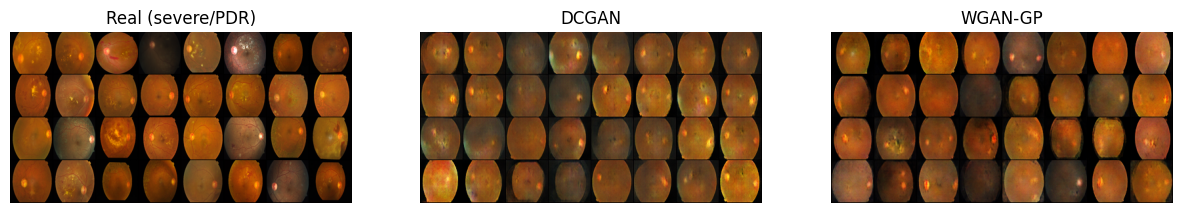

Real held-out (test) -> train NN distance : 6.36
dcgan seed 0 synthetic -> train NN distance: 10.68
dcgan seed 1 synthetic -> train NN distance: 10.33
dcgan seed 2 synthetic -> train NN distance: 8.57
wgangp seed 0 synthetic -> train NN distance: 8.15
wgangp seed 1 synthetic -> train NN distance: 10.31
wgangp seed 2 synthetic -> train NN distance: 9.64


In [ ]:
from torchvision.utils import make_grid
fig, axs = plt.subplots(1, 3, figsize=(15, 5.5))
panels = [("Real (severe/PDR)", Xtr[ytr == 1][:32]),
          ("DCGAN", synth(GENS["dcgan"][0], 32)),
          ("WGAN-GP", synth(GENS["wgangp"][0], 32))]
for ax, (name, imgs) in zip(axs, panels):
    ax.imshow(make_grid(imgs, nrow=8, padding=1).permute(1, 2, 0).numpy()); ax.set_title(name); ax.axis("off")
plt.savefig(f"{OUT}/real_vs_synthetic.png", dpi=150, bbox_inches="tight"); plt.show()

def nn_dist(a, b):
    A = a.flatten(1).float().div(255).to(device); B = b.flatten(1).float().div(255).to(device)
    return torch.cdist(A, B).min(1).values.cpu()
ref = Xtr[ytr == 1]
print(f"Real held-out (test) -> train NN distance : {nn_dist(Xte[yte==1], ref).mean():.2f}")
for kind in GENS:
    for s in GAN_SEEDS:
        print(f"{kind} seed {s} synthetic -> train NN distance: {nn_dist(synth(GENS[kind][s], 300), ref).mean():.2f}")

In [ ]:
!pip -q install torch-fidelity
import torch_fidelity, shutil
def dump(t, folder):
    shutil.rmtree(folder, ignore_errors=True); os.makedirs(folder)
    for i, x in enumerate(t):
        Image.fromarray(x.permute(1, 2, 0).numpy()).save(f"{folder}/{i}.png")
dump(Xtr[ytr == 1], "/content/kid_real")
for kind in GENS:
    dump(synth(GENS[kind][0], 300), f"/content/kid_{kind}")
    try:
        m = torch_fidelity.calculate_metrics(input1="/content/kid_real", input2=f"/content/kid_{kind}",
                                             cuda=use_amp, kid=True, kid_subset_size=100, kid_subsets=50, verbose=False)
        print(kind, "KID mean:", round(m["kernel_inception_distance_mean"], 4))
    except Exception as e:
        print(kind, "KID fail:", e)

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth


dcgan KID mean: 0.1214
wgangp KID mean: 0.0694


In [ ]:
CLS = 128
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def to01(xb, train=False):
    x = xb.to(device).float() / 255
    if train:
        x = aug_flip(x)
        x = torch.rot90(x, random.randint(0, 3), (2, 3))
        x = (x * (1 + 0.2 * (torch.rand(x.size(0), 1, 1, 1, device=device) - 0.5))).clamp(0, 1)
    if x.shape[-1] != CLS:
        x = F.interpolate(x, size=(CLS, CLS), mode="bilinear", align_corners=False)
    return x
def norm(x): return (x - MEAN) / STD
def prep(xb, train=False): return norm(to01(xb, train))

def make_clf():
    m = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
    m.fc = nn.Linear(512, 1)
    return m.to(device)

@torch.no_grad()
def predict(m, Xs, bs=256):
    m.eval(); ps = []
    for i in range(0, len(Xs), bs):
        with torch.autocast(device_type="cuda", enabled=use_amp):
            ps.append(torch.sigmoid(m(prep(Xs[i:i + bs])).squeeze(1)).float().cpu())
    return torch.cat(ps).numpy()

In [ ]:
EPOCHS, BS, LR = 12, 64, 1e-4      # test mode: EPOCHS = 2
SEEDS = [0, 1, 2]                  # test mode: [0]
METHODS = ["baseline", "baseline_matched", "class_weighted", "oversample", "dcgan_1x", "wgangp_1x"]
n0, npos = len(ytr), int(ytr.sum())
yv, yt = yva.numpy(), yte.numpy()

def build_train(method, seed):
    syn = {"dcgan_1x": "dcgan", "wgangp_1x": "wgangp"}.get(method)
    if syn is None:
        return Xtr, ytr
    G = GENS[syn][GAN_SEEDS[seed % len(GAN_SEEDS)]]
    return torch.cat([Xtr, synth(G, npos)]), torch.cat([ytr, torch.ones(npos, dtype=ytr.dtype)])

def run_clf(method, seed):
    Xs, ys = build_train(method, seed)
    ep = round(EPOCHS * (n0 + npos) / n0) if method == "baseline_matched" else EPOCHS
    set_seed(seed)
    m = make_clf()
    opt = torch.optim.AdamW(m.parameters(), lr=LR, weight_decay=1e-4)
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    pw = torch.tensor([float((ys == 0).sum()) / float((ys == 1).sum())], device=device) if method == "class_weighted" else None
    lossf = nn.BCEWithLogitsLoss(pos_weight=pw)
    if method == "oversample":
        w = torch.where(ys == 1, 0.5 / (ys == 1).sum(), 0.5 / (ys == 0).sum()).float()
    best, best_ep, best_state = -1, 0, None
    for e in range(ep):
        m.train()
        order = torch.multinomial(w, len(ys), replacement=True) if method == "oversample" else torch.randperm(len(ys))
        for i in range(0, len(ys), BS):
            b = order[i:i + BS]
            xb, yb = prep(Xs[b], True), ys[b].float().to(device)
            with torch.autocast(device_type="cuda", enabled=use_amp):
                loss = lossf(m(xb).squeeze(1).float(), yb)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        auc = roc_auc_score(yv, predict(m, Xva))
        if auc > best:
            best, best_ep = auc, e + 1
            best_state = {k: v.detach().cpu().clone() for k, v in m.state_dict().items()}
    m.load_state_dict(best_state)
    pv, pt = predict(m, Xva), predict(m, Xte)
    thr = float(np.quantile(pv[yv == 0], 0.90))
    row = dict(method=method, seed=seed, epochs=ep, best_epoch=best_ep, val_auc=best,
               test_auc=roc_auc_score(yt, pt), test_ap=average_precision_score(yt, pt),
               sens90=float((pt[yt == 1] > thr).mean()), spec_at_thr=float((pt[yt == 0] <= thr).mean()), thr=thr)
    return row, pt, best_state

ROWS, P, MODELS = [], {}, {}
for method in METHODS:
    for s in SEEDS:
        t0 = time.time()
        row, pt, st = run_clf(method, s)
        ROWS.append(row); P[(method, s)] = pt; MODELS[(method, s)] = st
        print(f"{method:17s} seed {s}  AUROC {row['test_auc']:.3f}  AP {row['test_ap']:.3f}  sens@90spec {row['sens90']:.3f}  ({time.time()-t0:.0f}s)")
R = pd.DataFrame(ROWS); R.to_csv(f"{OUT}/results_raw.csv", index=False)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 77.8MB/s]


baseline          seed 0  AUROC 0.918  AP 0.672  sens@90spec 0.740  (29s)
baseline          seed 1  AUROC 0.930  AP 0.737  sens@90spec 0.836  (21s)
baseline          seed 2  AUROC 0.924  AP 0.723  sens@90spec 0.740  (21s)
baseline_matched  seed 0  AUROC 0.918  AP 0.672  sens@90spec 0.740  (23s)
baseline_matched  seed 1  AUROC 0.930  AP 0.737  sens@90spec 0.836  (24s)
baseline_matched  seed 2  AUROC 0.924  AP 0.723  sens@90spec 0.740  (24s)
class_weighted    seed 0  AUROC 0.917  AP 0.675  sens@90spec 0.753  (20s)
class_weighted    seed 1  AUROC 0.926  AP 0.661  sens@90spec 0.753  (20s)
class_weighted    seed 2  AUROC 0.923  AP 0.730  sens@90spec 0.699  (24s)
oversample        seed 0  AUROC 0.923  AP 0.663  sens@90spec 0.753  (21s)
oversample        seed 1  AUROC 0.913  AP 0.643  sens@90spec 0.685  (20s)
oversample        seed 2  AUROC 0.908  AP 0.655  sens@90spec 0.767  (20s)
dcgan_1x          seed 0  AUROC 0.909  AP 0.675  sens@90spec 0.753  (23s)
dcgan_1x          seed 1  AUROC 0.923 

                 test_auc        test_ap        sens90        spec_at_thr  \
                     mean    std    mean    std   mean    std        mean   
method                                                                      
baseline            0.924  0.006   0.711  0.034  0.772  0.055       0.884   
baseline_matched    0.924  0.006   0.711  0.034  0.772  0.055       0.884   
class_weighted      0.922  0.005   0.689  0.037  0.735  0.032       0.892   
oversample          0.915  0.008   0.653  0.010  0.735  0.044       0.890   
dcgan_1x            0.914  0.008   0.691  0.023  0.744  0.008       0.908   
wgangp_1x           0.916  0.013   0.680  0.013  0.749  0.016       0.901   

                         
                    std  
method                   
baseline          0.019  
baseline_matched  0.019  
class_weighted    0.020  
oversample        0.015  
dcgan_1x          0.018  
wgangp_1x         0.008  

Bootstrap AUROC difference (95% CI):
dcgan_1x - baseline: -0.009  [-0.0

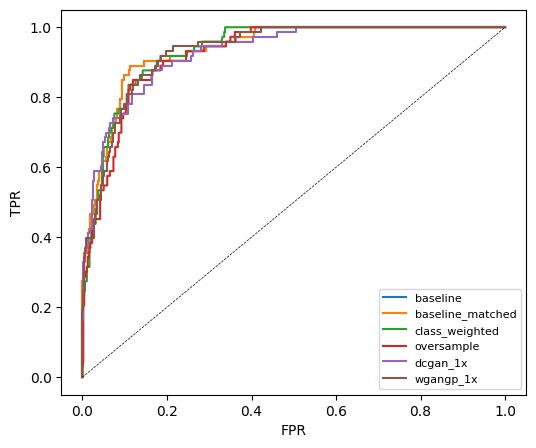

In [ ]:
summ = R.groupby("method")[["test_auc", "test_ap", "sens90", "spec_at_thr"]].agg(["mean", "std"]).loc[METHODS].round(3)
print(summ); summ.to_csv(f"{OUT}/results_summary.csv")

def avg_pred(method): return np.mean([P[(method, s)] for s in SEEDS], 0)
def boot_diff(m1, m2, B=1000):
    rng = np.random.default_rng(0); a, b = avg_pred(m1), avg_pred(m2); d = []
    for _ in range(B):
        i = rng.integers(0, len(yt), len(yt))
        if yt[i].sum() == 0: continue
        d.append(roc_auc_score(yt[i], a[i]) - roc_auc_score(yt[i], b[i]))
    return np.mean(d), np.percentile(d, [2.5, 97.5])
print("\nBootstrap AUROC difference (95% CI):")
for m1, m2 in [("dcgan_1x", "baseline"), ("dcgan_1x", "baseline_matched"), ("wgangp_1x", "baseline"),
               ("wgangp_1x", "baseline_matched"), ("wgangp_1x", "dcgan_1x"), ("class_weighted", "baseline")]:
    d, ci = boot_diff(m1, m2); print(f"{m1} - {m2}: {d:+.3f}  [{ci[0]:+.3f}, {ci[1]:+.3f}]")

plt.figure(figsize=(6, 5))
for m_ in METHODS:
    fpr, tpr, _ = roc_curve(yt, avg_pred(m_)); plt.plot(fpr, tpr, label=m_)
plt.plot([0, 1], [0, 1], "k--", lw=0.5); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.legend(fontsize=8)
plt.savefig(f"{OUT}/roc_curves.png", dpi=150, bbox_inches="tight"); plt.show()

Retina area fraction of image: 0.80
baseline   CAM mass inside retina: 0.799 +- 0.359
dcgan_1x   CAM mass inside retina: 0.637 +- 0.362
wgangp_1x  CAM mass inside retina: 0.551 +- 0.453


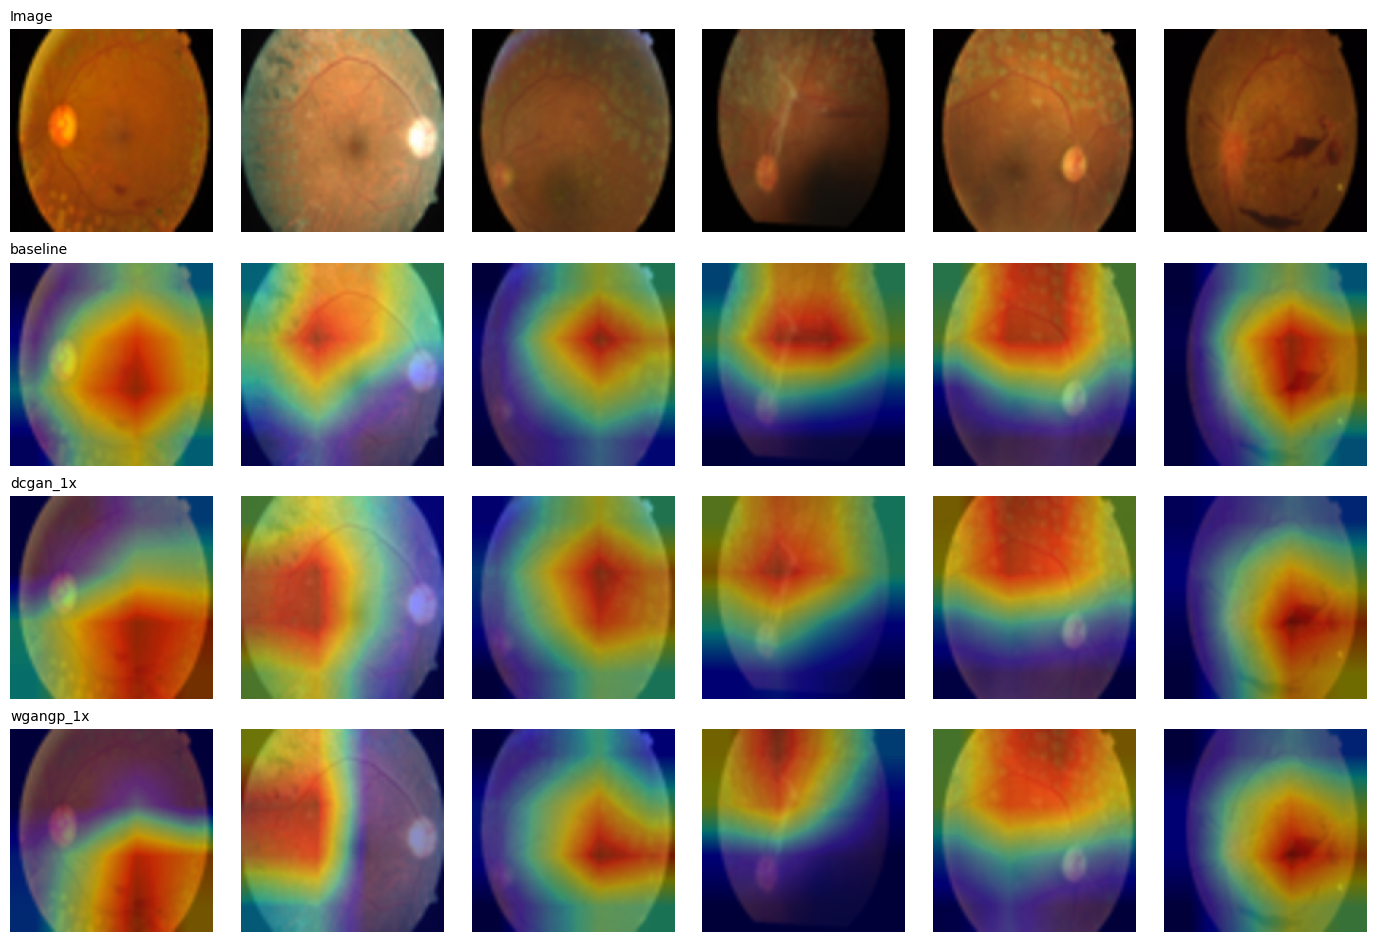

In [ ]:
def gradcam(model, xn):
    model.eval(); acts, grads = {}, {}
    def fwd(mod, inp, o):
        acts["a"] = o; o.register_hook(lambda g: grads.__setitem__("g", g))
    h = model.layer4.register_forward_hook(fwd)
    out = model(xn).squeeze(1)
    model.zero_grad(); out.sum().backward(); h.remove()
    w = grads["g"].mean((2, 3), keepdim=True)
    cam = F.relu((w * acts["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=xn.shape[-2:], mode="bilinear", align_corners=False)
    cam = cam - cam.amin((2, 3), keepdim=True); cam = cam / (cam.amax((2, 3), keepdim=True) + 1e-8)
    return cam.squeeze(1).detach().cpu()

def load_model(method, seed=0):
    m = make_clf(); m.load_state_dict(MODELS[(method, seed)]); return m.eval()

pos_te = torch.where(yte == 1)[0]
Xpos = Xte[pos_te]
x01_all = torch.cat([to01(Xpos[i:i + 64]).cpu() for i in range(0, len(Xpos), 64)])
mask = (x01_all.mean(1) > 0.08).float()
print(f"Retina area fraction of image: {mask.mean():.2f}")

CAM_METHODS = ["baseline", "dcgan_1x", "wgangp_1x"]
CAMS = {}
for method in CAM_METHODS:
    m = load_model(method)
    CAMS[method] = torch.cat([gradcam(m, norm(x01_all[i:i + 64].to(device))) for i in range(0, len(Xpos), 64)])
    inside = (CAMS[method] * mask).sum((1, 2)) / (CAMS[method].sum((1, 2)) + 1e-8)
    print(f"{method:10s} CAM mass inside retina: {inside.mean():.3f} +- {inside.std():.3f}")

pb = predict(load_model("baseline"), Xpos)
sel = np.argsort(-pb)[:6]
fig, axs = plt.subplots(4, 6, figsize=(14, 9.5))
for j, i in enumerate(sel):
    img = x01_all[i].permute(1, 2, 0).numpy()
    axs[0, j].imshow(img); axs[0, j].axis("off")
    for r, method in enumerate(CAM_METHODS, start=1):
        axs[r, j].imshow(img); axs[r, j].imshow(CAMS[method][i], cmap="jet", alpha=0.45); axs[r, j].axis("off")
for r, t in enumerate(["Image"] + CAM_METHODS):
    axs[r, 0].set_title(t, loc="left", fontsize=10)
plt.tight_layout(); plt.savefig(f"{OUT}/gradcam_comparison.png", dpi=150); plt.show()

In [16]:
print(R.groupby("method").best_epoch.apply(list))

method
baseline            [7, 9, 12]
baseline_matched    [7, 9, 12]
class_weighted      [7, 7, 12]
dcgan_1x            [11, 5, 7]
oversample          [7, 7, 11]
wgangp_1x            [4, 5, 7]
Name: best_epoch, dtype: object


In [17]:
def build_train(method, seed):
    if method.startswith(("dcgan_", "wgangp_")):
        kind, r = method.split("_")
        ratio = float(r.rstrip("x"))
        k = int(npos * ratio)
        G = GENS[kind][GAN_SEEDS[seed % len(GAN_SEEDS)]]
        return (torch.cat([Xtr, synth(G, k)]),
                torch.cat([ytr, torch.ones(k, dtype=ytr.dtype)]))
    return Xtr, ytr

RATIOS = [0.5, 2, 4]
SWEEP = [f"{k}_{r}x" for k in ("dcgan", "wgangp") for r in RATIOS]

for method in SWEEP:
    for s in SEEDS:
        row, pt, st = run_clf(method, s)
        ROWS.append(row); P[(method, s)] = pt; MODELS[(method, s)] = st
        print(f"{method:14s} seed {s}  AUROC {row['test_auc']:.3f}  AP {row['test_ap']:.3f}  sens@90spec {row['sens90']:.3f}")

R = pd.DataFrame(ROWS)
R.to_csv(f"{OUT}/results_raw_sweep.csv", index=False)
ALL = METHODS + SWEEP
sweep_summ = R.groupby("method")[["test_auc", "test_ap", "sens90"]].agg(["mean", "std"]).loc[ALL].round(3)
print(sweep_summ)
sweep_summ.to_csv(f"{OUT}/results_summary_sweep.csv")

dcgan_0.5x     seed 0  AUROC 0.927  AP 0.745  sens@90spec 0.753
dcgan_0.5x     seed 1  AUROC 0.921  AP 0.673  sens@90spec 0.795
dcgan_0.5x     seed 2  AUROC 0.923  AP 0.714  sens@90spec 0.699
dcgan_2x       seed 0  AUROC 0.910  AP 0.637  sens@90spec 0.808
dcgan_2x       seed 1  AUROC 0.919  AP 0.715  sens@90spec 0.712
dcgan_2x       seed 2  AUROC 0.896  AP 0.661  sens@90spec 0.726
dcgan_4x       seed 0  AUROC 0.918  AP 0.688  sens@90spec 0.740
dcgan_4x       seed 1  AUROC 0.925  AP 0.669  sens@90spec 0.795
dcgan_4x       seed 2  AUROC 0.935  AP 0.717  sens@90spec 0.753
wgangp_0.5x    seed 0  AUROC 0.938  AP 0.744  sens@90spec 0.836
wgangp_0.5x    seed 1  AUROC 0.914  AP 0.720  sens@90spec 0.740
wgangp_0.5x    seed 2  AUROC 0.929  AP 0.715  sens@90spec 0.740
wgangp_2x      seed 0  AUROC 0.913  AP 0.657  sens@90spec 0.822
wgangp_2x      seed 1  AUROC 0.908  AP 0.674  sens@90spec 0.671
wgangp_2x      seed 2  AUROC 0.913  AP 0.673  sens@90spec 0.712
wgangp_4x      seed 0  AUROC 0.932  AP 0

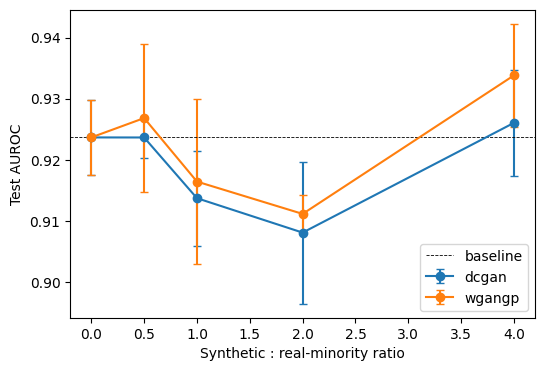


Bootstrap AUROC difference vs baseline (95% CI):
dcgan_0.5x     -0.001  [-0.015, +0.013]
dcgan_2x       -0.010  [-0.024, +0.004]
dcgan_4x       -0.001  [-0.015, +0.013]
wgangp_0.5x    +0.003  [-0.009, +0.016]
wgangp_2x      -0.010  [-0.023, +0.002]
wgangp_4x      +0.004  [-0.009, +0.018]


In [18]:
plt.figure(figsize=(6, 4))
xs = [0, 0.5, 1, 2, 4]
base = R[R.method == "baseline"].test_auc
for kind in ("dcgan", "wgangp"):
    means = [base.mean()] + [R[R.method == f"{kind}_{r}x"].test_auc.mean() for r in (0.5, 1, 2, 4)]
    stds  = [base.std()]  + [R[R.method == f"{kind}_{r}x"].test_auc.std()  for r in (0.5, 1, 2, 4)]
    plt.errorbar(xs, means, yerr=stds, marker="o", capsize=3, label=kind)
plt.axhline(base.mean(), color="k", ls="--", lw=0.6, label="baseline")
plt.xlabel("Synthetic : real-minority ratio"); plt.ylabel("Test AUROC"); plt.legend()
plt.savefig(f"{OUT}/ratio_sweep.png", dpi=150, bbox_inches="tight"); plt.show()

print("\nBootstrap AUROC difference vs baseline (95% CI):")
for m in SWEEP:
    d, ci = boot_diff(m, "baseline")
    print(f"{m:14s} {d:+.3f}  [{ci[0]:+.3f}, {ci[1]:+.3f}]")

In [19]:
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

BACKBONE = "efficientnet_b0"
def make_clf():
    if BACKBONE == "efficientnet_b0":
        m = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
        m.classifier[1] = nn.Linear(1280, 1)
    else:
        m = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
        m.fc = nn.Linear(512, 1)
    return m.to(device)

ROWS_EFF = []
for method in ["baseline", "class_weighted", "oversample", "dcgan_1x", "wgangp_1x"]:
    for s in SEEDS:
        row, _, _ = run_clf(method, s)
        row["backbone"] = "efficientnet_b0"
        ROWS_EFF.append(row)
        print(f"[EffNet-B0] {method:15s} seed {s}  AUROC {row['test_auc']:.3f}  AP {row['test_ap']:.3f}")

R_eff = pd.DataFrame(ROWS_EFF)
R_eff.to_csv(f"{OUT}/results_efficientnet.csv", index=False)
print(R_eff.groupby("method")[["test_auc", "test_ap", "sens90"]].agg(["mean", "std"]).round(3))

BACKBONE = "resnet18"   # wapas restore

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 48.5MB/s]


[EffNet-B0] baseline        seed 0  AUROC 0.936  AP 0.714
[EffNet-B0] baseline        seed 1  AUROC 0.907  AP 0.709
[EffNet-B0] baseline        seed 2  AUROC 0.896  AP 0.711
[EffNet-B0] class_weighted  seed 0  AUROC 0.924  AP 0.734
[EffNet-B0] class_weighted  seed 1  AUROC 0.929  AP 0.702
[EffNet-B0] class_weighted  seed 2  AUROC 0.930  AP 0.726
[EffNet-B0] oversample      seed 0  AUROC 0.944  AP 0.732
[EffNet-B0] oversample      seed 1  AUROC 0.941  AP 0.731
[EffNet-B0] oversample      seed 2  AUROC 0.929  AP 0.714
[EffNet-B0] dcgan_1x        seed 0  AUROC 0.923  AP 0.706
[EffNet-B0] dcgan_1x        seed 1  AUROC 0.912  AP 0.710
[EffNet-B0] dcgan_1x        seed 2  AUROC 0.909  AP 0.690
[EffNet-B0] wgangp_1x       seed 0  AUROC 0.915  AP 0.690
[EffNet-B0] wgangp_1x       seed 1  AUROC 0.924  AP 0.710
[EffNet-B0] wgangp_1x       seed 2  AUROC 0.895  AP 0.689
               test_auc        test_ap        sens90       
                   mean    std    mean    std   mean    std
method    